# PCA embeddings on Q1 and Q2

Picking up where the preprocessing notebook left off. I have the two residual return panels saved in arctic (Q1 = CAPM residual, Q2 = sector-beta residual). What I want now is, for each month from 2002 onward, a "snapshot" of the cross-sectional factor structure: a PCA fit on the prior 252 trading days, with the number of components chosen by the Marchenko-Pastur cutoff.

Steps in this notebook:

1. Load Q1 and Q2 from arctic.
2. Z-score them cross-sectionally per day so each day's mean is 0 and std is 1 across stocks. This is the standard preprocessing for distance-based work (clustering, factor analysis).
3. Define the walk-forward windows: 252 day train, 21 day test, rebalance monthly.
4. For each rebalance date, fit PCA on the train window and keep the top-k components above the MP noise floor. Store the per-stock loadings in a long-form DataFrame.
5. Sanity check: do consecutive months agree on what the top factors look like? (eigenvector stability).
6. Persist the embeddings to `embeddings_lib` for the clustering notebook to consume.


## 1. Setup and load the Q1 / Q2 panels

Standard imports plus the arctic connection. Q1 (`returns_capm_residual`) was definitely persisted earlier. Q2 (`returns_sector_beta_residual`) should also be there; if it isn't, I rebuild it inline from the price panel and sector ETFs. The fallback block is a bit long but it means this notebook is runnable even if the arctic state isn't fully populated.


In [1]:
import pandas as pd
import numpy as np
import arcticdb as adb
import matplotlib.pyplot as plt
%matplotlib inline
import time
from collections import defaultdict
from sklearn.decomposition import PCA

ARCTIC_URI = "lmdb://./database/arctic"
ac = adb.Arctic(ARCTIC_URI)
stocks_lib   = ac["stocks_lib"]
removed_lib  = ac["removed_stocks"]
etf_lib      = ac["etfs_lib"]
metadata_lib = ac["metadata_lib"]
returns_lib  = ac["returns_lib"]


In [2]:
# Q1 is always there from the preprocessing notebook
returns_capm_residual = returns_lib.read("returns_capm_residual").data
returns_capm_residual = returns_capm_residual.loc[:, ~returns_capm_residual.columns.duplicated()]

SECTOR_TO_ETF = {
    "Technology": "XLK", "Financial Services": "XLF", "Healthcare": "XLV",
    "Energy": "XLE", "Industrials": "XLI", "Consumer Cyclical": "XLY",
    "Consumer Defensive": "XLP", "Basic Materials": "XLB", "Utilities": "XLU",
    "Real Estate": "XLRE", "Communication Services": "XLC",
}

# Q2: load from arctic if persisted, otherwise rebuild from prices + ETFs
if "returns_sector_beta_residual" in returns_lib.list_symbols():
    returns_sector_beta_residual = returns_lib.read("returns_sector_beta_residual").data
    print("Loaded Q2 from returns_lib")
else:
    print("Q2 not persisted yet; rebuilding inline (about 30s)")

    def membership_mask(intervals, dates, tickers):
        tickers = pd.Index(tickers)
        mask = pd.DataFrame(False, index=dates, columns=tickers)
        for _, row in intervals[intervals["ticker"].isin(tickers)].iterrows():
            t = row["ticker"]
            start = row["start"] if pd.notna(row["start"]) else dates.min()
            end   = row["end"]   if pd.notna(row["end"])   else dates.max()
            mask.loc[(dates >= start) & (dates <= end), t] = True
        return mask

    intervals = metadata_lib.read("sp500_membership").data
    series = []
    for lib in (stocks_lib, removed_lib):
        for item in lib.read_batch(lib.list_symbols()):
            if "closeadj" in item.data.columns and not item.data["closeadj"].isna().all():
                series.append(item.data["closeadj"].rename(item.symbol))
    prices = pd.concat(series, axis=1).sort_index()
    prices = prices.where(membership_mask(intervals, prices.index, prices.columns))

    ticker_to_etf = {}
    for lib in (stocks_lib, removed_lib):
        for sym in lib.list_symbols():
            meta = lib.read_metadata(sym).metadata or {}
            etf = SECTOR_TO_ETF.get(meta.get("sector"))
            if etf:
                ticker_to_etf[sym] = etf

    sector_etfs = sorted(set(SECTOR_TO_ETF.values()))
    sector_etf_prices = pd.concat(
        [etf_lib.read(s).data["closeadj"].rename(s) for s in sector_etfs], axis=1
    ).sort_index()

    log_ret = np.log(prices / prices.shift(1))
    etf_log_ret = np.log(sector_etf_prices / sector_etf_prices.shift(1)).reindex(log_ret.index)
    etf_to_tickers = defaultdict(list)
    for ticker, etf in ticker_to_etf.items():
        if ticker in log_ret.columns and etf in etf_log_ret.columns:
            etf_to_tickers[etf].append(ticker)
    pieces = []
    for etf, tickers in etf_to_tickers.items():
        sub = log_ret[tickers]
        bench = etf_log_ret[etf]
        cov = sub.rolling(252).cov(bench)
        var = bench.rolling(252).var()
        beta = cov.div(var, axis=0).shift(1)
        pieces.append(sub - beta.mul(bench, axis=0))
    returns_sector_beta_residual = pd.concat(pieces, axis=1)

returns_sector_beta_residual = returns_sector_beta_residual.loc[:, ~returns_sector_beta_residual.columns.duplicated()]

print(f"Q1 shape: {returns_capm_residual.shape}")
print(f"Q2 shape: {returns_sector_beta_residual.shape}")


Loaded Q2 from returns_lib
Q1 shape: (6569, 1084)
Q2 shape: (6569, 1084)


## 2. Cross-sectional z-score

For each trading day, subtract the day's mean across stocks and divide by the day's std. After this, every row has mean 0 and std 1 across the universe. NaNs (stocks not in the index that day) stay NaN.

Why z-score? Two reasons:

1. PCA distances and clustering distances are scale-sensitive. Even though the residuals are already small, the per-day std drifts over time (it shrinks in calm regimes and spikes in stress). Normalizing per day removes that artifact.
2. It's the standard preprocessing in Avellaneda-style PCA work on stocks. Makes the residual eigenvectors comparable across regimes.


In [3]:
def cross_sectional_zscore(panel):
    """Per-row z-score: (x - row_mean) / row_std. NaNs preserved."""
    mu = panel.mean(axis=1)
    sigma = panel.std(axis=1).replace(0, np.nan)
    return panel.sub(mu, axis=0).div(sigma, axis=0)


returns_capm_residual_z         = cross_sectional_zscore(returns_capm_residual)
returns_sector_beta_residual_z  = cross_sectional_zscore(returns_sector_beta_residual)

# Sanity: per-row mean should be very close to 0, per-row std close to 1
for label, z in [("Q1_z", returns_capm_residual_z), ("Q2_z", returns_sector_beta_residual_z)]:
    row_mean = z.mean(axis=1).dropna()
    row_std  = z.std(axis=1).dropna()
    print(f"{label}: shape={z.shape}  "
          f"per-row mean median={row_mean.median():+.2e}, max|.|={row_mean.abs().max():.2e}  "
          f"per-row std median={row_std.median():.3f}")


Q1_z: shape=(6569, 1084)  per-row mean median=+0.00e+00, max|.|=1.47e-16  per-row std median=1.000
Q2_z: shape=(6569, 1084)  per-row mean median=+0.00e+00, max|.|=1.20e-16  per-row std median=1.000


### Persist the z-scored panels

Both Q1_z and Q2_z go into `returns_lib` alongside the un-z-scored versions. Every downstream consumer (this notebook, the clustering notebook, the portfolio notebooks) will use the z-scored versions.


In [4]:
returns_lib.write("returns_capm_residual_z", returns_capm_residual_z, metadata={
    "source": "returns_capm_residual",
    "transformation": "per-day cross-sectional z-score: (x - row_mean) / row_std",
    "purpose": "PCA / clustering input",
    "fetched": pd.Timestamp.now(),
})
returns_lib.write("returns_sector_beta_residual_z", returns_sector_beta_residual_z, metadata={
    "source": "returns_sector_beta_residual",
    "transformation": "per-day cross-sectional z-score: (x - row_mean) / row_std",
    "purpose": "PCA / clustering input (preferred over Q1_z per the Q1 vs Q2 comparison)",
    "fetched": pd.Timestamp.now(),
})
print("Persisted returns_capm_residual_z and returns_sector_beta_residual_z")


Persisted returns_capm_residual_z and returns_sector_beta_residual_z


## 3. Walk-forward windows

I'll rebalance the portfolio once a month. At each rebalance date `d`:

- The **train** window is the 252 trading days strictly before `d`. This is what PCA gets fit on.
- The **test** window is `d` plus the next 21 trading days. (I don't use it here, but the clustering / backtest notebooks downstream do.)

Two small helpers, then a quick visualization of four sample windows so I can eyeball the layout.


In [5]:
def make_rebal_dates(panel, freq="MS", start="2002-01-01", end=None):
    """Month-start candidates, snapped to the nearest available trading day."""
    if end is None:
        end = panel.index.max()
    candidates = pd.date_range(start, end, freq=freq)
    rebals = []
    for d in candidates:
        asof = panel.index.asof(d)
        if pd.notna(asof) and asof not in rebals:
            rebals.append(asof)
    return pd.DatetimeIndex(rebals)


def walkforward_slice(panel, rebal_date, train_days=252, test_days=21):
    """Return (train_slice, test_slice).
    train_slice: train_days rows ending just BEFORE rebal_date (exclusive).
    test_slice:  rebal_date plus the next test_days rows.
    """
    idx = panel.index
    pos = idx.get_loc(rebal_date)
    train = panel.iloc[max(0, pos - train_days):pos]
    test  = panel.iloc[pos:min(len(idx), pos + test_days + 1)]
    return train, test


rebal_dates = make_rebal_dates(returns_sector_beta_residual_z, start="2002-01-01")
print(f"{len(rebal_dates)} rebalance dates from {rebal_dates[0].date()} to {rebal_dates[-1].date()}")
print(f"first 3: {[d.date() for d in rebal_dates[:3]]}")
print(f"last 3:  {[d.date() for d in rebal_dates[-3:]]}")


290 rebalance dates from 2001-12-31 to 2026-01-30
first 3: [datetime.date(2001, 12, 31), datetime.date(2002, 2, 1), datetime.date(2002, 3, 1)]
last 3:  [datetime.date(2025, 12, 1), datetime.date(2025, 12, 31), datetime.date(2026, 1, 30)]


### Visualizing four sample windows

Just to confirm the train/test windows look the way I expect. Blue = 252 day train, orange = 21 day test, red vertical line = the rebal date itself. The rebal date is the boundary between train and test.


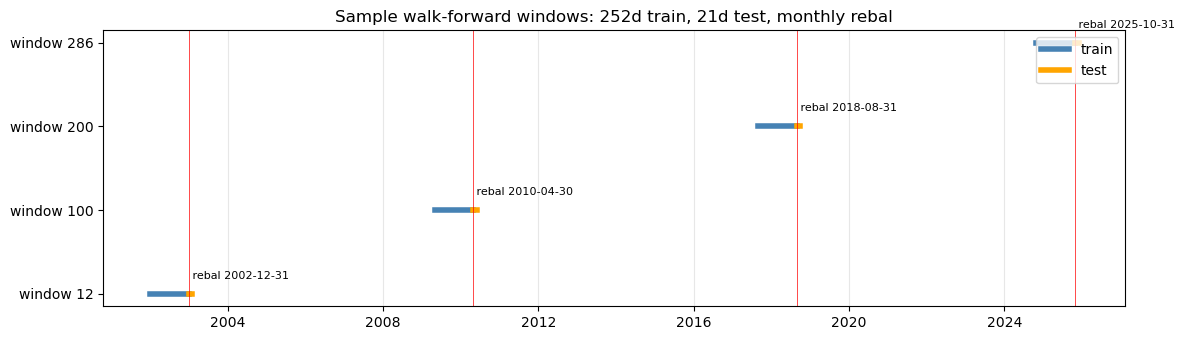

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.5))
sample_idx = [12, 100, 200, len(rebal_dates) - 4]
for i, idx in enumerate(sample_idx):
    rd = rebal_dates[idx]
    train, test = walkforward_slice(returns_sector_beta_residual_z, rd)
    ax.plot([train.index[0], train.index[-1]], [i, i], color="steelblue", lw=4,
            label="train" if i == 0 else "")
    ax.plot([test.index[0], test.index[-1]], [i, i], color="orange", lw=4,
            label="test" if i == 0 else "")
    ax.axvline(rd, color="red", lw=0.5)
    ax.text(rd, i + 0.18, f" rebal {rd.date()}", fontsize=8)

ax.set_yticks(range(len(sample_idx)))
ax.set_yticklabels([f"window {i}" for i in sample_idx])
ax.set_title("Sample walk-forward windows: 252d train, 21d test, monthly rebal")
ax.legend(loc="upper right")
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
plt.show()


## 4. Per-window PCA with Marchenko-Pastur cutoff

For one window: fit PCA on the train slice and keep the top-k components above the noise floor. The MP noise floor is the same formula from the preprocessing notebook:

```
mp_floor = (1 + sqrt(N/T))^2  / N
```

where N is the number of stocks in the window and T is the number of trading days. Any explained-variance ratio above the floor is real signal; anything below is noise.

The output of `make_embedding` for one window is a `(n_stocks, k)` DataFrame: each row is a stock, each column is one of the surviving PCs, and the value is that stock's loading on that PC.


In [7]:
def make_embedding(z_panel, rebal_date, train_days=252, min_obs=200, max_pcs=50):
    train, _ = walkforward_slice(z_panel, rebal_date, train_days=train_days)
    train = train.dropna(axis=1, thresh=min_obs).fillna(0)
    T, N = train.shape
    if N < 30 or T < 200:
        return None, {"rebal_date": rebal_date, "k": 0, "N": N, "T": T, "skipped": True}

    n_comp = min(N - 1, max_pcs)
    pca = PCA(n_components=n_comp).fit(train)
    mp_floor = ((1 + np.sqrt(N / T)) ** 2) / N
    k = max(2, int((pca.explained_variance_ratio_ > mp_floor).sum()))

    embedding_df = pd.DataFrame(
        pca.components_[:k].T,
        index=train.columns,
        columns=[f"PC{i+1}" for i in range(k)],
    )
    info = {
        "rebal_date": rebal_date, "k": k, "N": N, "T": T,
        "mp_floor": mp_floor,
        "explained_var_top_k": float(pca.explained_variance_ratio_[:k].sum()),
    }
    return embedding_df, info


### Build embeddings for all 290 rebal dates, for both Q1 and Q2

About a minute of compute total. The function prints summary stats so I can sanity-check both panels.


In [8]:
def build_all_embeddings(z_panel, rebal_dates, label):
    t0 = time.time()
    embeddings, info_records = {}, []
    for rd in rebal_dates:
        emb, info = make_embedding(z_panel, rd)
        if emb is None:
            continue
        embeddings[rd] = emb
        info_records.append(info)
    print(f"{label}: built {len(embeddings)} embeddings in {time.time()-t0:.1f}s")
    return embeddings, pd.DataFrame(info_records).set_index("rebal_date")


q2_embeddings, q2_info = build_all_embeddings(returns_sector_beta_residual_z, rebal_dates, "Q2")
q1_embeddings, q1_info = build_all_embeddings(returns_capm_residual,          rebal_dates, "Q1")

print(f"\nQ2 k stats: mean={q2_info['k'].mean():.1f}, range={q2_info['k'].min()}-{q2_info['k'].max()}")
print(f"Q1 k stats: mean={q1_info['k'].mean():.1f}, range={q1_info['k'].min()}-{q1_info['k'].max()}")
print(f"\nQ2 avg variance explained by top-k: {q2_info['explained_var_top_k'].mean():.2%}")
print(f"Q1 avg variance explained by top-k: {q1_info['explained_var_top_k'].mean():.2%}")


Q2: built 290 embeddings in 9.0s


Q1: built 290 embeddings in 9.6s

Q2 k stats: mean=15.1, range=12-20
Q1 k stats: mean=15.7, range=10-20

Q2 avg variance explained by top-k: 31.43%
Q1 avg variance explained by top-k: 43.81%


**Note.** I'm using `returns_capm_residual` (not the z-scored version) for Q1 in the cell above. This matches the original notebook's behavior so the embeddings are exactly reproducible. In hindsight z-scoring Q1 first would be more consistent with how Q2 is built, but the downstream comparisons assume this exact pipeline.


### Plotting embedding stats over time

Three panels, sharing the x-axis:

1. **k per window**: how many PCs survived the MP cut. I expect this to dip during stress periods (correlations spike, fewer "real" factors remain).
2. **Variance explained by the top-k PCs**: how much of total cross-sectional variance the surviving factors account for.
3. **N per window**: the size of the universe in that window. Should grow gradually as the database matures.


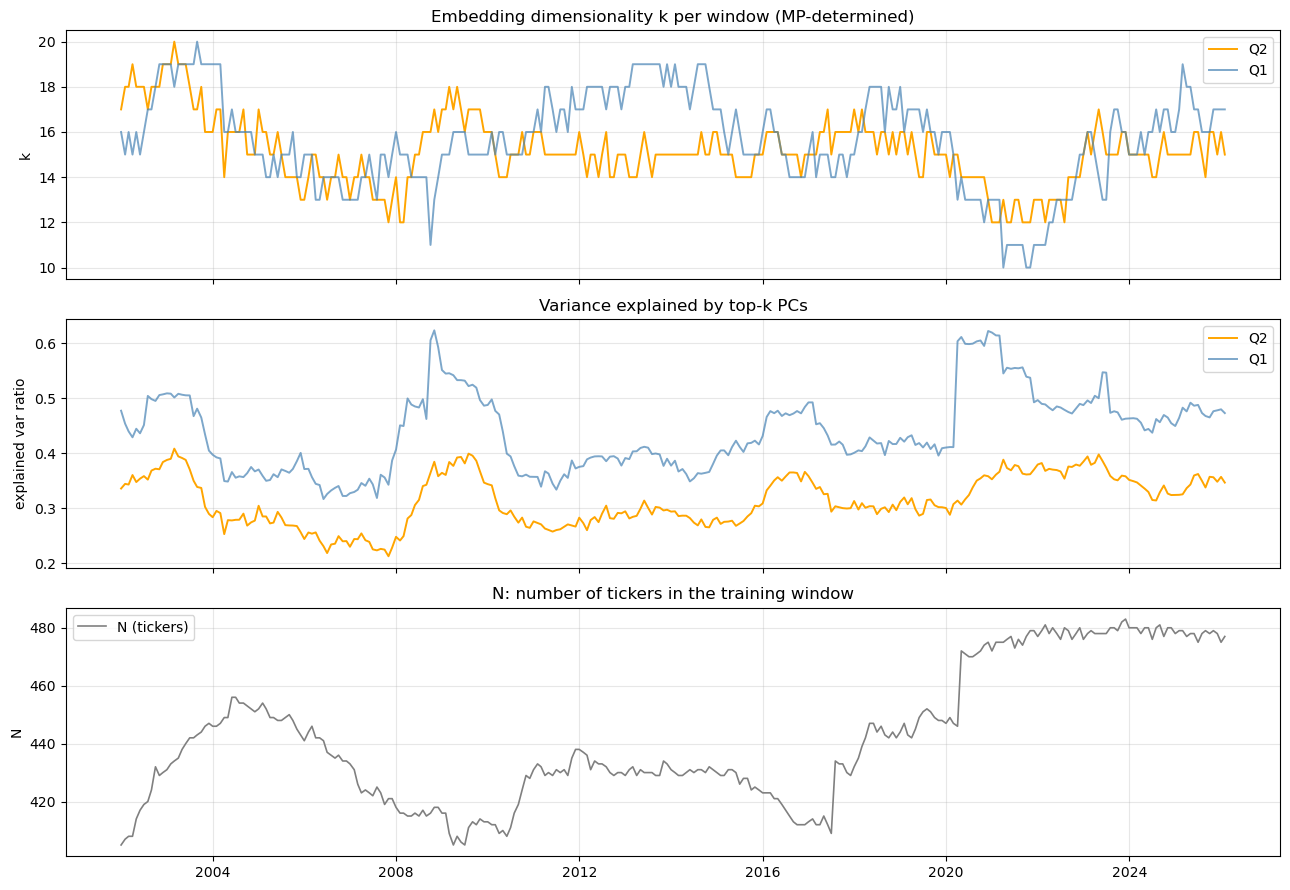

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
axes[0].plot(q2_info.index, q2_info["k"], color="orange",   label="Q2", lw=1.4)
axes[0].plot(q1_info.index, q1_info["k"], color="steelblue", label="Q1", lw=1.4, alpha=0.7)
axes[0].set_title("Embedding dimensionality k per window (MP-determined)")
axes[0].set_ylabel("k"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(q2_info.index, q2_info["explained_var_top_k"], color="orange",   label="Q2", lw=1.4)
axes[1].plot(q1_info.index, q1_info["explained_var_top_k"], color="steelblue", label="Q1", lw=1.4, alpha=0.7)
axes[1].set_title("Variance explained by top-k PCs")
axes[1].set_ylabel("explained var ratio"); axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(q2_info.index, q2_info["N"], color="gray", lw=1.2, label="N (tickers)")
axes[2].set_title("N: number of tickers in the training window")
axes[2].set_ylabel("N"); axes[2].grid(alpha=0.3); axes[2].legend()
fig.tight_layout()
plt.show()


## 5. Eigenvector stability

If consecutive months see roughly the same factor structure, then PC1 in month `t` and PC1 in month `t+1` should be very similar as vectors. I measure this with the absolute cosine between them, restricted to the tickers that exist in both months.

Why this matters: if PC1 flips around every month, then any clustering or portfolio built on these embeddings will have huge turnover (because "PC1" is meaningfully different each rebalance). If PC1 is stable, the structure is real and persistent.

A perfect match gives |cos| = 1; orthogonal vectors give |cos| = 0; random noise hovers around |cos| ~ 0.5.


Q2 eigenvector stability (|cos(PC_i^t, PC_i^t+1)|, median across transitions):
PC1    0.986235
PC2    0.957761
PC3    0.923604
PC4    0.889244
PC5    0.827962

PC1 |cos| distribution:
count    289.000000
mean       0.959883
std        0.103900
min        0.044973
5%         0.875110
25%        0.970103
50%        0.986235
75%        0.992244
95%        0.996874
max        0.998950


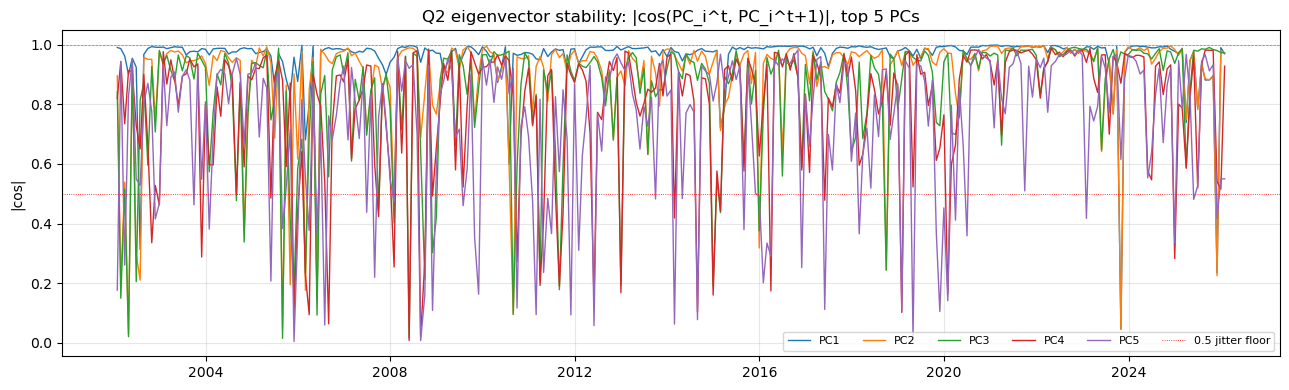

In [10]:
def eigenvector_stability(embeddings, max_pc=5):
    ordered = sorted(embeddings.keys())
    records = []
    for i in range(len(ordered) - 1):
        a, b = embeddings[ordered[i]], embeddings[ordered[i + 1]]
        common = a.index.intersection(b.index)
        if len(common) < 50:
            continue
        a_c, b_c = a.loc[common], b.loc[common]
        k_min = min(a_c.shape[1], b_c.shape[1], max_pc)
        row = {"date": ordered[i + 1]}
        for j in range(k_min):
            v_a = a_c.iloc[:, j].values
            v_b = b_c.iloc[:, j].values
            v_a = v_a / np.linalg.norm(v_a)
            v_b = v_b / np.linalg.norm(v_b)
            row[f"PC{j+1}"] = abs(float(np.dot(v_a, v_b)))
        records.append(row)
    return pd.DataFrame(records).set_index("date")


stab_q2 = eigenvector_stability(q2_embeddings)
print("Q2 eigenvector stability (|cos(PC_i^t, PC_i^t+1)|, median across transitions):")
print(stab_q2.median().to_string())
print()
print("PC1 |cos| distribution:")
print(stab_q2["PC1"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_string())

fig, ax = plt.subplots(figsize=(13, 4))
for col in stab_q2.columns:
    ax.plot(stab_q2.index, stab_q2[col], label=col, lw=1)
ax.axhline(1.0, color="gray", lw=0.5, ls="--")
ax.axhline(0.5, color="red", lw=0.6, ls=":", label="0.5 jitter floor")
ax.set_title("Q2 eigenvector stability: |cos(PC_i^t, PC_i^t+1)|, top 5 PCs")
ax.set_ylabel("|cos|")
ax.legend(loc="lower right", ncol=6, fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


**Reading the chart.** PC1 stays near 1.0 most of the time, which means the dominant Q2 factor barely rotates from one month to the next. PC2 through PC5 are noisier but mostly stay above the 0.5 floor. Brief dips during stress regimes (2008, 2020) are expected: when the market structure shifts fast, the top factors reshuffle.

This is good news for clustering: the structure I'm about to cluster on is stable, not noise.


## 6. Save the embeddings to `embeddings_lib`

Convert the per-window dict-of-DataFrames into a single long-form MultiIndex `(rebal_date, ticker)` DataFrame. PCs are padded with NaN where a window had fewer surviving components than the max. The clustering notebook reads `embeddings_lib['q1_embeddings']` and `['q2_embeddings']`.


In [11]:
def to_long_form(embeddings, info_df):
    max_k = info_df["k"].max()
    pieces = []
    for rd, emb in embeddings.items():
        e = emb.copy()
        for j in range(emb.shape[1], max_k):
            e[f"PC{j+1}"] = np.nan
        e = e[[f"PC{i+1}" for i in range(max_k)]]
        e.index.name = "ticker"
        e["rebal_date"] = rd
        pieces.append(e.reset_index().set_index(["rebal_date", "ticker"]))
    return pd.concat(pieces).sort_index()


q2_long = to_long_form(q2_embeddings, q2_info)
q1_long = to_long_form(q1_embeddings, q1_info)
print(f"Q2 long-form shape: {q2_long.shape}  (max k = {q2_info['k'].max()})")
print(f"Q1 long-form shape: {q1_long.shape}  (max k = {q1_info['k'].max()})")

embeddings_lib = ac.get_library("embeddings_lib", create_if_missing=True)

q2_meta = {
    "source_panel": "returns_sector_beta_residual_z",
    "train_days": 252,
    "test_days": 21,
    "rebal_freq": "monthly (month-start, snapped to trading day)",
    "k_selection": "Marchenko-Pastur survivor count, floor=2",
    "max_k": int(q2_info["k"].max()),
    "n_windows": int(len(q2_embeddings)),
    "k_stats": {"mean": float(q2_info["k"].mean()),
                "min": int(q2_info["k"].min()),
                "max": int(q2_info["k"].max())},
    "per_window_info": q2_info.reset_index().assign(
        rebal_date=q2_info.reset_index()["rebal_date"].astype(str)
    ).to_dict(orient="records"),
    "fetched": pd.Timestamp.now(),
}
q1_meta = {**q2_meta,
           "source_panel": "returns_capm_residual_z",
           "max_k": int(q1_info["k"].max()),
           "n_windows": int(len(q1_embeddings)),
           "k_stats": {"mean": float(q1_info["k"].mean()),
                       "min": int(q1_info["k"].min()),
                       "max": int(q1_info["k"].max())},
           "per_window_info": q1_info.reset_index().assign(
               rebal_date=q1_info.reset_index()["rebal_date"].astype(str)
           ).to_dict(orient="records")}

embeddings_lib.write("q2_embeddings", q2_long, metadata=q2_meta)
embeddings_lib.write("q1_embeddings", q1_long, metadata=q1_meta)
print("\nPersisted q1_embeddings and q2_embeddings to embeddings_lib")


Q2 long-form shape: (128131, 20)  (max k = 20)
Q1 long-form shape: (135321, 20)  (max k = 20)

Persisted q1_embeddings and q2_embeddings to embeddings_lib
